# **JMP leave-one-out stepwise analysis** 

**Source:** `LOO-stepwise.xlsx` (the individual JMP leave-one-out regression fits in columns A–E of each sheet). **No regression is refitted**.

We create two reference visualizations:

1. A **potassium heatmap** across four outcomes, showing first-step associations and second-step models when one additional predictor is sufficiently stable.
2. A **BAIBA / MFI Reduced Motivation** figure with selection frequency, model fit, and unstandardized regression coefficients.

### Selection and aggregation rules

- The denominator is **every saved LOO iteration for that outcome**. A first-step selection counts only when the corresponding JMP fit contains exactly the primary marker. If a first-step model includes a different marker, it remains in the denominator.
- For each outcome, identify the most common additional variable selected in **Step 2**, conditional on the first JMP model containing only BAIBA or potassium. Each Step 2 fit must contain **exactly two terms**: the primary marker and that additional predictor.
- Display a Step 2 model only when this *exact pair* appears in **at least 75% of all saved folds**. Otherwise, the Step 2 panel remains blank for that outcome.
- Coefficients and adj-R² are summarized as **mean ± sample standard deviation across saved JMP folds with exactly the same model specification**. We never pool coefficients from different adjustment sets.
- The first-step frequency and exact-pair frequency both use **all saved folds**. 

In [1]:
from pathlib import Path
from collections import Counter, defaultdict
import csv
import math
import posixpath
import re
import statistics
from zipfile import ZipFile
from xml.etree import ElementTree as ET

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import patches
from IPython.display import display

# Put the Excel workbook in the same directory as this notebook, or change SOURCE_FILE.
SOURCE_FILE = Path('./../processed-11-2026/LOO-stepwise.xlsx')
OUTPUT_DIR = Path('./../processed-11-2026/jmp_stepwise_figures_all_folds')

# A pair is displayed only when it occurs in at least this proportion of ALL folds.
MIN_STEP2_FREQUENCY_ALL_FOLDS = 0.75
EXPORT_DPI = 220
R2_AXIS_LABEL = 'Adj-$R^2$'  # The Excel source labels this 'R2', not 'Adjusted R2'.

assert 0 < MIN_STEP2_FREQUENCY_ALL_FOLDS <= 1
if not SOURCE_FILE.is_file():
    raise FileNotFoundError(f'Cannot find {SOURCE_FILE}. Place LOO-stepwise.xlsx beside the notebook.')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('Input workbook:', SOURCE_FILE.resolve())
print('Figures/tables:', OUTPUT_DIR.resolve())
print(f'Exact-pair stability threshold: {MIN_STEP2_FREQUENCY_ALL_FOLDS:.0%} of all LOO folds')


Input workbook: /Users/vdamario/Library/CloudStorage/OneDrive-NovaSoutheasternUniversity 2/NSU/Research/CLOSED/Metabolic Study/_MATERIAL related to submission/processed-11-2026/LOO-stepwise.xlsx
Figures/tables: /Users/vdamario/Library/CloudStorage/OneDrive-NovaSoutheasternUniversity 2/NSU/Research/CLOSED/Metabolic Study/_MATERIAL related to submission/processed-11-2026/jmp_stepwise_figures_all_folds
Exact-pair stability threshold: 75% of all LOO folds


## 1. Read only the individual JMP results

JMP stores each LOO iteration as a numbered row, followed by its intercept, regression slopes, `R2`, AIC, and BIC. A separate Excel column represents each step of the JMP model sequence. The reader below extracts **only A–E** (the individual model results); all cells to their right, including manually calculated summary percentages, are ignored.

This uses Python's standard-library ZIP/XML reader so that the notebook does not depend on a local Excel installation. Cached cell values, not Excel formulas, are used.


In [2]:
MAIN_NS = '{http://schemas.openxmlformats.org/spreadsheetml/2006/main}'
REL_NS = '{http://schemas.openxmlformats.org/officeDocument/2006/relationships}'
PKG_NS = '{http://schemas.openxmlformats.org/package/2006/relationships}'
CELL_RE = re.compile(r'^([A-Z]+)([0-9]+)$')

def parse_xlsx(path):
    """Return {sheet_name: {excel_row_number: {column_letter: cached_value}}}."""
    with ZipFile(path) as archive:
        entries = set(archive.namelist())
        shared = []
        if 'xl/sharedStrings.xml' in entries:
            root = ET.fromstring(archive.read('xl/sharedStrings.xml'))
            for si in root.findall(MAIN_NS+'si'):
                shared.append(''.join(t.text or '' for t in si.iter(MAIN_NS+'t')))

        book = ET.fromstring(archive.read('xl/workbook.xml'))
        rel_root = ET.fromstring(archive.read('xl/_rels/workbook.xml.rels'))
        targets = {rel.get('Id'): rel.get('Target') for rel in rel_root.findall(PKG_NS+'Relationship')}

        result = {}
        for sh in book.findall('.//'+MAIN_NS+'sheet'):
            name = sh.get('name')
            rid = sh.get(REL_NS+'id')
            target = targets[rid]
            member = target.lstrip('/') if target.startswith('/') else posixpath.normpath('xl/'+target)
            root = ET.fromstring(archive.read(member))
            rows = {}
            for row in root.findall('.//'+MAIN_NS+'sheetData/'+MAIN_NS+'row'):
                row_num = int(row.get('r'))
                cells = {}
                for cell in row.findall(MAIN_NS+'c'):
                    match = CELL_RE.match(cell.get('r', ''))
                    if not match:
                        continue
                    col = match.group(1)
                    if col not in ('A', 'B', 'C', 'D', 'E'):
                        continue  # Never read helper tables or summary cells on the right.
                    cell_type = cell.get('t')
                    v = cell.find(MAIN_NS+'v')
                    if cell_type == 'inlineStr':
                        inline = cell.find(MAIN_NS+'is')
                        value = ''.join(x.text or '' for x in inline.iter(MAIN_NS+'t')) if inline is not None else None
                    elif v is None or v.text is None:
                        value = None
                    elif cell_type == 's':
                        value = shared[int(v.text)]
                    elif cell_type in ('str','e'):
                        value = v.text
                    elif cell_type == 'b':
                        value = v.text == '1'
                    else:
                        try:
                            value = float(v.text)
                        except ValueError:
                            value = v.text
                    if value is not None:
                        cells[col] = value
                if cells:
                    rows[row_num] = cells
            result[name] = rows
    return result

sheets = parse_xlsx(SOURCE_FILE)
for sheet_name, rows in sheets.items():
    print(f'{sheet_name:26} {len(rows):3} populated rows')

BAIBA - MFI                211 populated rows
MFI Mental Fatigue         179 populated rows
Mental Health Summary      185 populated rows
HAD                        178 populated rows
Well Being                 185 populated rows


## 2. Normalize the LOO model paths

We convert the individual JMP fits into long-form records, including the outcome, left-out iteration, step number, included predictors, intercept, each coefficient, and the saved `R2`. The long-form exports allow independent inspection of every number shown in the figures.


In [3]:
SHEET_CONFIG = {
    'BAIBA - MFI': ('MFI Reduced Motivation', 'BAIBA'),
    'MFI Mental Fatigue': ('MFI Mental Fatigue', 'Potassium'),
    'HAD': ('HAD Depression', 'Potassium'),
    'Well Being': ('SF-36 Emotional Well-Being', 'Potassium'),
    'Mental Health Summary': ('Mental Health Summary', 'Potassium'),
}
STEP_COLS = ('B', 'C', 'D', 'E')

def is_numeric(x):
    return isinstance(x, (int,float)) and math.isfinite(float(x)) and not isinstance(x, bool)

def parse_models(sheets):
    models, coefficients = [], []
    for name, (outcome, primary) in SHEET_CONFIG.items():
        rows = sheets[name]
        starts = sorted(r for r, values in rows.items()
                        if is_numeric(values.get('A')) and float(values['A']).is_integer())
        for i, start in enumerate(starts):
            end = starts[i+1] if i+1 < len(starts) else max(rows)+1
            fold = int(rows[start]['A'])
            block = {str(rows[r].get('A')): rows[r] for r in range(start+1,end)
                     if r in rows and isinstance(rows[r].get('A'), str)}
            for step, col in enumerate(STEP_COLS, start=1):
                intercept = block.get('Intercept', {}).get(col)
                r2 = block.get('R2', {}).get(col)
                if not (is_numeric(intercept) and is_numeric(r2)):
                    continue
                terms = {term: item[col] for term,item in block.items()
                         if term not in ('Intercept','R2','AIC','BIC') and is_numeric(item.get(col))}
                model = dict(sheet=name, outcome=outcome, primary=primary,
                             fold_id=fold, step=step, intercept=float(intercept),
                             r2=float(r2), aic=block.get('AIC',{}).get(col),
                             bic=block.get('BIC',{}).get(col),
                             n_predictors=len(terms), terms=terms,
                             model_signature=' + '.join(sorted(terms)))
                models.append(model)
                for term, estimate in [('Intercept', intercept), *terms.items()]:
                    coefficients.append(dict(sheet=name, outcome=outcome, fold_id=fold,
                                             step=step, model_signature=model['model_signature'],
                                             predictor=term, coefficient=float(estimate)))
    return models, coefficients

models, coefficients = parse_models(sheets)
models_by_outcome = defaultdict(list)
for model in models:
    models_by_outcome[model['outcome']].append(model)
print(f'{len(models):,} model fits, {len(coefficients):,} coefficient estimates')
for name, (outcome, primary) in SHEET_CONFIG.items():
    all_ids = set(m['fold_id'] for m in models_by_outcome[outcome])
    print(f'{outcome:31} {len(all_ids):2} LOO iterations, {len(models_by_outcome[outcome]):3} saved models')

292 model fits, 813 coefficient estimates
MFI Reduced Motivation          27 LOO iterations,  64 saved models
MFI Mental Fatigue              24 LOO iterations,  56 saved models
HAD Depression                  24 LOO iterations,  56 saved models
SF-36 Emotional Well-Being      25 LOO iterations,  58 saved models
Mental Health Summary           25 LOO iterations,  58 saved models


## 3. Choose the most stable *second* predictor for each outcome

A candidate pair qualifies only if all of the following hold:

1. The saved Step 1 model contains exactly BAIBA (or potassium).
2. The saved Step 2 model contains exactly that primary marker **plus one** additional predictor.
3. The additional predictor is the most frequently observed Step 2 choice across folds.
4. That exact pair is selected in at least `MIN_STEP2_FREQUENCY_ALL_FOLDS` of **all** saved LOO iterations for the outcome.

If no pair reaches the threshold, **Step 2 is not summarized or drawn** for that outcome. This prevents a model with weak selection stability from appearing as if it were consistently supported. The runner-up candidates remain in the audit export.

For Step 1, calculate means and SDs over folds selecting exactly the one-predictor primary-marker model. For qualifying Step 2 models, calculate means and SDs over folds selecting the **same exact two-predictor specification**.


In [4]:
def summarize_numbers(values):
    """Mean and sample SD (ddof=1), using only the supplied identical-specification fits."""
    xs = [float(x) for x in values]
    return {
        'n': len(xs),
        'mean': statistics.mean(xs) if xs else float('nan'),
        'sd': statistics.stdev(xs) if len(xs) > 1 else float('nan'),
    }


def coefficient_stats(model_subset, terms):
    """Unstandardized coefficients; no pooling across distinct model specifications."""
    result = {}
    for term in terms:
        if term == 'Intercept':
            values = [m['intercept'] for m in model_subset]
        else:
            values = [m['terms'][term] for m in model_subset]
        result[term] = summarize_numbers(values)
    return result


summaries = {}
secondary_frequencies = []
selection_audit = []

for sheet, (outcome, primary) in SHEET_CONFIG.items():
    by_fold = defaultdict(dict)
    for fit in models_by_outcome[outcome]:
        if fit['step'] in by_fold[fit['fold_id']]:
            raise ValueError(f'Duplicate fit: {outcome}, fold {fit["fold_id"]}, step {fit["step"]}')
        by_fold[fit['fold_id']][fit['step']] = fit
    n_folds = len(by_fold)
    if not n_folds:
        raise ValueError(f'No individual LOO records found for {outcome}')

    step1 = [fits[1] for fits in by_fold.values()
             if 1 in fits and set(fits[1]['terms']) == {primary}]

    # Count the exact primary + secondary model at Step 2, not its component
    # coefficients in larger/differently adjusted models.
    step2_by_secondary = defaultdict(list)
    for fold_id, fits in by_fold.items():
        if not (1 in fits and set(fits[1]['terms']) == {primary} and 2 in fits):
            continue
        model2 = fits[2]
        terms = set(model2['terms'])
        if len(terms) != 2 or primary not in terms:
            continue
        additional = next(iter(terms - {primary}))
        step2_by_secondary[additional].append(model2)

    ranking = sorted(step2_by_secondary,
                     key=lambda secondary: (-len(step2_by_secondary[secondary]), secondary))
    leader = ranking[0] if ranking else None
    leading_models = step2_by_secondary[leader] if leader else []
    leading_share = len(leading_models) / n_folds
    stable = leader is not None and leading_share >= MIN_STEP2_FREQUENCY_ALL_FOLDS
    # Never report coefficient summaries for an insufficiently stable pair.
    step2 = leading_models if stable else []

    for rank, secondary in enumerate(ranking, start=1):
        count = len(step2_by_secondary[secondary])
        secondary_frequencies.append({
            'outcome': outcome, 'primary': primary, 'rank': rank,
            'additional_predictor': secondary, 'exact_pair': f'{primary} + {secondary}',
            'n_selected': count, 'n_all_folds': n_folds,
            'frequency_all_folds': count / n_folds,
            'is_leading_pair': secondary == leader,
            'meets_stability_threshold': secondary == leader and stable,
        })

    rec = {
        'sheet': sheet, 'outcome': outcome, 'primary': primary,
        'n_all': n_folds, 'step1_models': step1,
        'n_step1': len(step1), 'freq1': len(step1)/n_folds,
        'leading_secondary': leader,
        'leading_n': len(leading_models),
        'leading_freq_all': leading_share,
        'step2_stable': stable,
        'secondary': leader if stable else None,
        'step2_models': step2,
        'n_step2': len(step2),
        'freq2': leading_share if stable else float('nan'),
        'step1_r2': summarize_numbers([m['r2'] for m in step1]),
        'step2_r2': summarize_numbers([m['r2'] for m in step2]),
        'step1_coefs': coefficient_stats(step1, ['Intercept', primary]),
        'step2_coefs': coefficient_stats(step2, ['Intercept', primary, leader]) if stable else {},
    }
    summaries[outcome] = rec
    selection_audit.append({
        'outcome': outcome, 'primary': primary, 'all_folds': n_folds,
        'step1_n': len(step1), 'step1_frequency': rec['freq1'],
        'most_frequent_secondary': leader or '',
        'leading_pair_n': len(leading_models),
        'leading_pair_frequency': leading_share,
        'threshold': MIN_STEP2_FREQUENCY_ALL_FOLDS,
        'step2_shown': stable,
        'status': 'stable exact pair' if stable else 'NO STABLE SECOND PREDICTOR',
    })

print(f'{"Outcome":31} {"Step 1":>10} {"Leading Step 2 pair":>34} {"Pair":>10}  Status')
print('-'*113)
for rec in summaries.values():
    print(f'{rec["outcome"]:31} '
          f'{rec["n_step1"]:2}/{rec["n_all"]:<7} '
          f'{str(rec["leading_secondary"] or "none"):>34} '
          f'{rec["leading_n"]:2}/{rec["n_all"]:<7} '
          f'{"SHOW" if rec["step2_stable"] else "HIDE"}')


Outcome                             Step 1                Leading Step 2 pair       Pair  Status
-----------------------------------------------------------------------------------------------------------------
MFI Reduced Motivation          27/27                                     BMI 21/27      SHOW
MFI Mental Fatigue              23/24                                  8-OHdG 21/24      SHOW
HAD Depression                  17/24                 alpha-Arninoadipic Acid 10/24      HIDE
SF-36 Emotional Well-Being      24/25                                  AA/EPA 21/25      SHOW
Mental Health Summary           23/25                                Vaccanic 14/25      HIDE


## 4. Export normalized results and selection audit

Every table below is computed **only from columns A–E**. In particular, there is no `FREQUENCY_MODE` switch and no use of the workbook's helper percentages.

- `jmp_models_long.csv`: all individual LOO fits and exact predictor signatures.
- `jmp_coefficients_long.csv`: individual unstandardized coefficient estimates.
- `secondary_predictor_frequencies.csv`: every observed second predictor, ordered by stability.
- `selection_audit.csv`: denominators, winning pairs, and explicit inclusion/exclusion decisions.
- `figure_model_summary.csv` / `figure_coefficient_summary.csv`: only the models and coefficients actually displayed. Unstable Step 2 models are not included.


In [5]:
def export_csv(path, rows, fieldnames=None):
    rows = list(rows)
    if fieldnames is None:
        fieldnames = list(rows[0]) if rows else []
    with path.open('w', newline='', encoding='utf-8-sig') as f:
        writer = csv.DictWriter(f, fieldnames=fieldnames, extrasaction='ignore')
        writer.writeheader()
        writer.writerows(rows)
    print('Saved:', path)

raw_models = [{k: v for k, v in model.items() if k != 'terms'} |
              {'predictors': ' | '.join(sorted(model['terms']))} for model in models]
export_csv(OUTPUT_DIR/'jmp_models_long.csv', raw_models)
export_csv(OUTPUT_DIR/'jmp_coefficients_long.csv', coefficients)
export_csv(OUTPUT_DIR/'secondary_predictor_frequencies.csv', secondary_frequencies,
           fieldnames=['outcome','primary','rank','additional_predictor','exact_pair',
                       'n_selected','n_all_folds','frequency_all_folds',
                       'is_leading_pair','meets_stability_threshold'])
export_csv(OUTPUT_DIR/'selection_audit.csv', selection_audit)

model_summary = []
coefficient_summary = []
for outcome, rec in summaries.items():
    for step, fits, stats, coef_stats, selected_model, frequency in (
        (1, rec['step1_models'], rec['step1_r2'], rec['step1_coefs'],
         rec['primary'], rec['freq1']),
        (2, rec['step2_models'], rec['step2_r2'], rec['step2_coefs'],
         f'{rec["primary"]} + {rec["secondary"]}' if rec['step2_stable'] else None,
         rec['freq2']),
    ):
        if step == 2 and not rec['step2_stable']:
            continue
        model_summary.append({
            'outcome': outcome, 'step': step, 'model': selected_model,
            'n_selected': len(fits), 'n_all_folds': rec['n_all'],
            'selection_frequency': frequency,
            'r2_mean': stats['mean'], 'r2_sd': stats['sd'],
        })
        for term, st in coef_stats.items():
            coefficient_summary.append({
                'outcome': outcome, 'step': step, 'model': selected_model,
                'term': term, 'n_selected': st['n'],
                'coefficient_mean': st['mean'], 'coefficient_sd': st['sd'],
            })
export_csv(OUTPUT_DIR/'figure_model_summary.csv', model_summary)
export_csv(OUTPUT_DIR/'figure_coefficient_summary.csv', coefficient_summary)

# Integrity checks: summaries must be based on the same exact model signature.
for outcome, rec in summaries.items():
    for m in rec['step1_models']:
        assert set(m['terms']) == {rec['primary']}
    for m in rec['step2_models']:
        assert rec['step2_stable']
        assert set(m['terms']) == {rec['primary'], rec['secondary']}
    assert rec['n_step1'] <= rec['n_all']
    assert rec['n_step2'] <= rec['n_all']
    assert rec['n_step2'] == 0 or rec['freq2'] >= MIN_STEP2_FREQUENCY_ALL_FOLDS

Saved: ../processed-11-2026/jmp_stepwise_figures_all_folds/jmp_models_long.csv
Saved: ../processed-11-2026/jmp_stepwise_figures_all_folds/jmp_coefficients_long.csv
Saved: ../processed-11-2026/jmp_stepwise_figures_all_folds/secondary_predictor_frequencies.csv
Saved: ../processed-11-2026/jmp_stepwise_figures_all_folds/selection_audit.csv
Saved: ../processed-11-2026/jmp_stepwise_figures_all_folds/figure_model_summary.csv
Saved: ../processed-11-2026/jmp_stepwise_figures_all_folds/figure_coefficient_summary.csv


## 5. Figure 1 — Potassium heatmap

Each left-hand cell shows Step 1 potassium's frequency among all folds, and the corresponding mean ± sample SD of the potassium slope. On the right, **only the most common eligible two-variable Step 2 model** is shown; all other cells are left blank.

No Step 2 model is shown for outcomes that do not meet the stability criterion. The additional-predictor columns are populated dynamically from the **qualifying pairs** found in the individual records.


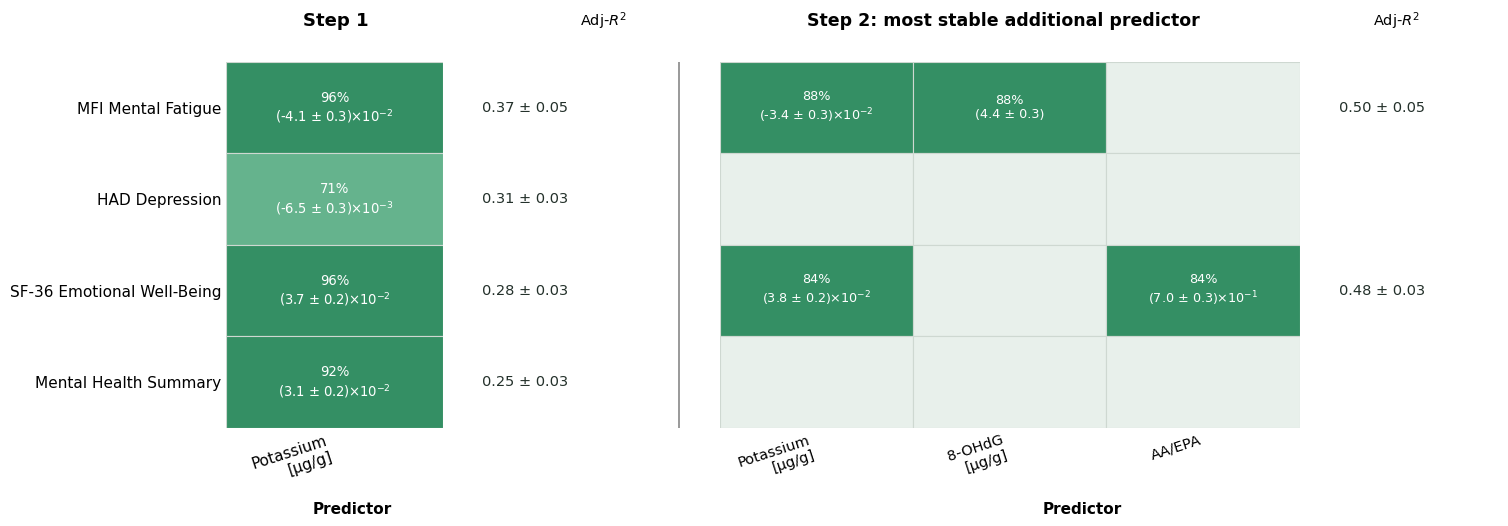

Saved: ../processed-11-2026/jmp_stepwise_figures_all_folds/potassium_stepwise_heatmap.png ../processed-11-2026/jmp_stepwise_figures_all_folds/potassium_stepwise_heatmap.pdf


In [6]:
GREEN = '#348f64'
PALE = '#e8f0eb'
GRID = '#ced8d1'
TEXT = '#24312b'
POTASSIUM_OUTCOMES = [
    'MFI Mental Fatigue', 'HAD Depression',
    'SF-36 Emotional Well-Being', 'Mental Health Summary',
]

# Dynamically identify only qualifying additional predictors (no hard-coded pairs).
STABLE_SECONDARIES = list(dict.fromkeys(
    summaries[outcome]['secondary'] for outcome in POTASSIUM_OUTCOMES
    if summaries[outcome]['step2_stable']
))
SECOND_STEP_COLS = ['Potassium', *STABLE_SECONDARIES]

from decimal import Decimal, ROUND_HALF_UP

def rounded1(x):
    return str(Decimal(f'{x:.9g}').quantize(Decimal('0.1'), rounding=ROUND_HALF_UP))

def sci_mean_sd(mean, sd):
    """Compact labels while retaining the correct coefficient units."""
    if not math.isfinite(mean):
        return 'NA'
    if not math.isfinite(sd):
        return f'{mean:.3g} (SD unavailable)'
    if abs(mean) < 1e-12:
        return f'{mean:.2f} ± {sd:.2f}'
    exponent = math.floor(math.log10(abs(mean)))
    scale = 10.0 ** exponent
    a, b = mean/scale, sd/scale
    if exponent == 0:
        return f'({rounded1(a)} ± {rounded1(b)})'
    return f'({rounded1(a)} ± {rounded1(b)})×10$^{{{exponent}}}$'

def r2_caption(stat):
    return (f'{stat["mean"]:.2f} ± {stat["sd"]:.2f}'
            if stat['n'] >= 2 else '—')

def predictor_axis_label(term):
    return {'Potassium': 'Potassium\n[µg/g]',
            '8-OHdG': '8-OHdG\n[µg/g]',
            'AA/EPA': 'AA/EPA'}.get(term, term)


def draw_potassium():
    n = len(POTASSIUM_OUTCOMES)
    cols = len(SECOND_STEP_COLS)
    fig = plt.figure(figsize=(15.7, 6.1), facecolor='white')
    gs = fig.add_gridspec(1, 5, width_ratios=[1.32, 0.97, 0.06, 1.18*cols, 0.99],
                          left=.175, right=.985, top=.80, bottom=.20, wspace=.16)
    ax_s1 = fig.add_subplot(gs[0,0])
    ax_r1 = fig.add_subplot(gs[0,1])
    ax_div = fig.add_subplot(gs[0,2])
    ax_s2 = fig.add_subplot(gs[0,3])
    ax_r2 = fig.add_subplot(gs[0,4])
    for ax, ncols in [(ax_s1, 1), (ax_s2, cols)]:
        ax.set_xlim(0, ncols); ax.set_ylim(n,0)
        ax.set_xticks([i+.5 for i in range(ncols)])
        ax.set_yticks([i+.5 for i in range(n)])
        ax.tick_params(length=0)
        for side in ax.spines.values(): side.set_visible(False)
    ax_s1.set_yticklabels(POTASSIUM_OUTCOMES, fontsize=11)
    ax_s1.set_xticklabels(['Potassium\n[µg/g]'], rotation=18, ha='right', fontsize=11)
    ax_s2.set_yticklabels([])
    ax_s2.set_xticklabels([predictor_axis_label(c) for c in SECOND_STEP_COLS],
                          rotation=18, ha='right', fontsize=10.5)

    for i, outcome in enumerate(POTASSIUM_OUTCOMES):
        rec = summaries[outcome]
        p1 = rec['freq1']
        fill = GREEN if p1 >= .85 else '#65b38d'
        ax_s1.add_patch(patches.Rectangle((0,i),1,1,facecolor=fill,
                                          edgecolor=GRID,lw=.8))
        st = rec['step1_coefs']['Potassium']
        ax_s1.text(.5,i+.5,
                   f'{p1*100:.0f}%\n{sci_mean_sd(st["mean"],st["sd"])}',
                   ha='center', va='center', color='white', fontsize=9.5)

        # A row is blank if no stable pair has been found for this outcome.
        for j, term in enumerate(SECOND_STEP_COLS):
            show = rec['step2_stable'] and term in ('Potassium', rec['secondary'])
            ax_s2.add_patch(patches.Rectangle((j,i),1,1,
                    facecolor=GREEN if show else PALE, edgecolor=GRID,lw=.8))
            if show:
                st = rec['step2_coefs'][term]
                ax_s2.text(j+.5,i+.5,
                       f'{rec["freq2"]*100:.0f}%\n{sci_mean_sd(st["mean"],st["sd"])}',
                       ha='center', va='center', color='white', fontsize=9.2)
        ax_r1.text(.02,i+.5,r2_caption(rec['step1_r2']),
                   ha='left', va='center', fontsize=10.5, color=TEXT)
        if rec['step2_stable']:
            ax_r2.text(.02,i+.5,r2_caption(rec['step2_r2']),
                       ha='left', va='center', fontsize=10.5, color=TEXT)

    for ax in (ax_r1,ax_r2,ax_div):
        ax.set_axis_off(); ax.set_ylim(n,0)
    ax_div.plot([.5,.5],[0,n],color='#888',lw=1.2)
    fig.text(.245,.86,'Step 1',ha='center',fontsize=13,fontweight='bold')
    fig.text(.67,.86,'Step 2: most stable additional predictor',ha='center',
             fontsize=12.5,fontweight='bold')
    fig.text(.415,.86,R2_AXIS_LABEL,ha='center',fontsize=10.5)
    fig.text(.92,.86,R2_AXIS_LABEL,ha='center',fontsize=10.5)
    fig.text(.255,.06,'Predictor',ha='center',fontweight='bold',fontsize=11)
    fig.text(.72,.06,'Predictor',ha='center',fontweight='bold',fontsize=11)
    # fig.text(.175,.006,
    #          f'Individual JMP fits • percentages use all LOO folds • Step 2 shown only at ≥{MIN_STEP2_FREQUENCY_ALL_FOLDS:.0%} • mean ± sample SD',
    #          fontsize=8.4,color='#5e6b64')
    out_png = OUTPUT_DIR/'potassium_stepwise_heatmap.png'
    out_pdf = OUTPUT_DIR/'potassium_stepwise_heatmap.pdf'
    fig.savefig(out_png,dpi=EXPORT_DPI,facecolor='white',bbox_inches='tight')
    fig.savefig(out_pdf,facecolor='white',bbox_inches='tight')
    display(fig); plt.close(fig)
    print('Saved:',out_png, out_pdf)

draw_potassium()


## 6. Figure 2 — BAIBA and MFI Reduced Motivation

Panel A reports the Step 1 and qualifying exact-pair Step 2 selection frequencies **out of all LOO folds**. Panel B displays the adjusted `R2` values, and Panel C displays unstandardized coefficient estimates.

Step 2 means and SDs use only folds with the **same BAIBA + additional predictor** specification. If the pair does not meet the stability cutoff, the notebook shows Step 1 only, rather than reporting an unstable Step 2 model.


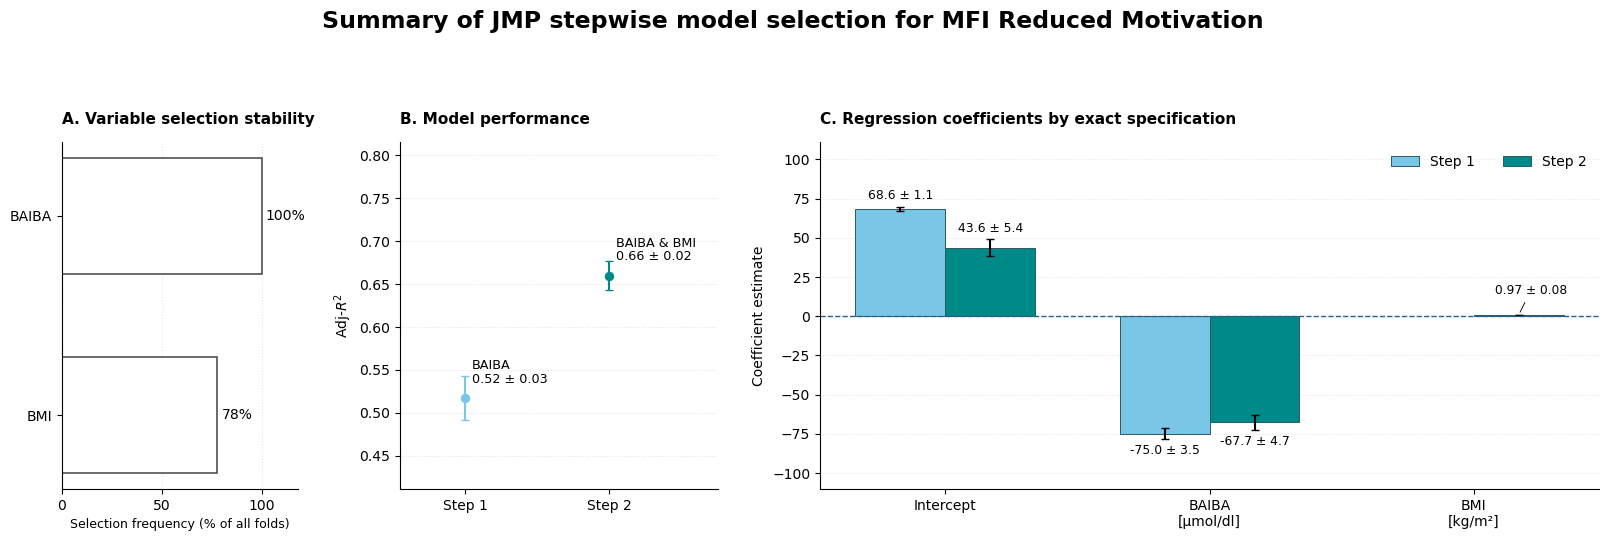

Saved: ../processed-11-2026/jmp_stepwise_figures_all_folds/baiba_reduced_motivation_three_panel.png ../processed-11-2026/jmp_stepwise_figures_all_folds/baiba_reduced_motivation_three_panel.pdf


In [7]:
BLUE = '#79c6e6'
TEAL = '#008989'


def draw_baiba():
    rec = summaries['MFI Reduced Motivation']
    stable = rec['step2_stable']
    sec = rec['secondary'] if stable else None
    fig = plt.figure(figsize=(16.8,6.3),facecolor='white')
    gs = fig.add_gridspec(1,3,width_ratios=[1.15,1.55,3.8],
                          left=.065,right=.98,top=.77,bottom=.22,wspace=.23)
    ax_a,ax_b,ax_c = [fig.add_subplot(gs[0,i]) for i in range(3)]
    fig.suptitle('Summary of JMP stepwise model selection for MFI Reduced Motivation',
                 fontsize=17,fontweight='bold',y=.98)
    for ax,heading in zip((ax_a,ax_b,ax_c),
        ('A. Variable selection stability','B. Model performance',
         'C. Regression coefficients by exact specification')):
        ax.set_title(heading,loc='left',fontsize=11,fontweight='bold',pad=13)

    # Panel A: model-selection frequencies, consistently divided by all folds.
    labels = [rec['primary']] + ([sec] if stable else [])
    percent = [rec['freq1']*100] + ([rec['freq2']*100] if stable else [])
    ypos = np.arange(len(labels))
    ax_a.barh(ypos,percent,height=.58,color='white',edgecolor='#444',linewidth=1.1)
    ax_a.set_yticks(ypos,labels); ax_a.invert_yaxis()
    ax_a.set_xlim(0,118); ax_a.set_xticks([0,50,100])
    ax_a.set_xlabel('Selection frequency (% of all folds)',fontsize=9)
    ax_a.grid(axis='x',ls=':',alpha=.3); ax_a.set_axisbelow(True)
    for y,p in zip(ypos,percent):
        ax_a.text(p+2,y,f'{p:.0f}%',va='center',fontsize=10)
    if not stable:
        ax_a.text(.04,.15,'No stable second predictor',transform=ax_a.transAxes,
                  fontsize=9,color='#5e6b64')

    # Panel B: R2 from exactly the models displayed.
    xs=[0]+([1] if stable else [])
    stats=[rec['step1_r2']]+([rec['step2_r2']] if stable else [])
    means=[s['mean'] for s in stats]; sds=[s['sd'] for s in stats]
    for k,(x,mu,sd) in enumerate(zip(xs,means,sds)):
        ax_b.errorbar(x,mu,yerr=sd,fmt='o',markersize=5.8,capsize=3,
                      color=BLUE if k==0 else TEAL,lw=1.5)
        name=rec['primary'] if k==0 else f'{rec["primary"]} & {sec}'
        ax_b.annotate(f'{name}\n{mu:.2f} ± {sd:.2f}',(x,mu),
                      xytext=(5,11),textcoords='offset points',fontsize=9.2)
    ax_b.set_xticks(xs,['Step 1']+(['Step 2'] if stable else []))
    ax_b.set_xlim(-.45,1.75 if stable else .9)
    ax_b.set_ylabel(R2_AXIS_LABEL,fontsize=10)
    ax_b.set_ylim(min(means)-max(sds)-.08,max(means)+max(sds)+.13)
    ax_b.grid(axis='y',ls=':',alpha=.35); ax_b.set_axisbelow(True)

    # Panel C: coefficients in original units, grouped by exact model signature.
    terms=['Intercept',rec['primary']]+([sec] if stable else [])
    c1=rec['step1_coefs'];c2=rec['step2_coefs']
    bars=np.arange(len(terms),dtype=float)
    width=.34
    for term_stats,color,label,offset in [
        (c1,BLUE,'Step 1',-width/2),
        *(([(c2,TEAL,'Step 2',width/2)]) if stable else []),
    ]:
        present=[(i,term) for i,term in enumerate(terms) if term in term_stats]
        xpos=[bars[i]+offset for i,term in present]
        mu=[term_stats[term]['mean'] for _,term in present]
        sd=[term_stats[term]['sd'] for _,term in present]
        ax_c.bar(xpos,mu,yerr=sd,width=width,color=color,label=label,
                 capsize=3,edgecolor='#2b5960',linewidth=.7)
        for xx,m,err in zip(xpos,mu,sd):
            if not math.isfinite(m):
                continue
            dy=(abs(err) if math.isfinite(err) else 0)+3
            if abs(m)<2:
                ax_c.annotate(f'{m:.2f} ± {err:.2f}',(xx,m),
                              xytext=(xx+.045,14),textcoords='data',fontsize=8.8,
                              ha='center',arrowprops={'arrowstyle':'-','lw':.65})
            else:
                ax_c.text(xx,m+(dy if m>=0 else -dy),f'{m:.1f} ± {err:.1f}',
                          ha='center',va='bottom' if m>=0 else 'top',fontsize=8.9)
    ax_c.axhline(0,ls='--',lw=1,color='#26628c')
    ax_c.set_xticks(bars,[
        'Intercept',f'{rec["primary"]}\n[µmol/dl]',
        *([f'{sec}\n[kg/m²]' if sec=='BMI' else str(sec)] if stable else [])
    ])
    ax_c.set_ylabel('Coefficient estimate',fontsize=10)
    ax_c.grid(axis='y',ls=':',alpha=.3); ax_c.set_axisbelow(True)
    ax_c.legend(frameon=False,ncol=2,loc='upper right')
    ax_c.set_ylim(-110,111)
    for ax in (ax_a,ax_b,ax_c):
        ax.spines[['top','right']].set_visible(False)
    # fig.text(.067,.073,
    #          f'Unstandardized coefficients • only identical model specifications • all-fold frequencies • Step 2 stability ≥{MIN_STEP2_FREQUENCY_ALL_FOLDS:.0%}',
    #          fontsize=8.9,color='#52605a')
    png=OUTPUT_DIR/'baiba_reduced_motivation_three_panel.png'
    pdf=OUTPUT_DIR/'baiba_reduced_motivation_three_panel.pdf'
    fig.savefig(png,dpi=EXPORT_DPI,facecolor='white',bbox_inches='tight')
    fig.savefig(pdf,facecolor='white',bbox_inches='tight')
    display(fig); plt.close(fig)
    print('Saved:',png,pdf)

draw_baiba()


## 7. Interpretation and checks

1. **The percentages use the full denominator:** the number of saved LOO iterations for that outcome, including iterations selecting another variable in Step 1 or Step 2.
2. **The stability rule applies to exact pairs, not individual coefficients.** The most common second predictor must occur together with the primary marker in the Step 2 model in at least 75% of *all* folds to be displayed. A second predictor appearing in a larger model does **not** qualify.
3. **The SD is descriptive.** Overlapping LOO training sets are strongly correlated; the sample SD of coefficients across folds is neither an independent-sampling uncertainty estimate nor a confidence interval.
5. **HAD iteration 15 is not patient ID 15.** 